In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)


In [3]:
df = pd.read_csv("uber.csv")

In [4]:
df.head()

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [5]:
print("First Five Records:")
print(df.head())

First Five Records:
   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.772647          

In [6]:
print("\nDataset Shape:")
print(df.shape)


Dataset Shape:
(200000, 9)


In [7]:
print("\nDataset Information:")
print(df.info())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  object 
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  object 
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), object(2)
memory usage: 13.7+ MB
None


In [8]:
print("\nMissing Values:")
print(df.isnull().sum())


Missing Values:
Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64


In [9]:
# Remove unnecessary index column if present
df.drop(columns=["Unnamed: 0", "key"],
        errors="ignore", inplace=True)


In [10]:
# Remove duplicate records
df.drop_duplicates(inplace=True)

In [11]:
# Convert pickup_datetime into datetime format
df["pickup_datetime"] = pd.to_datetime(
    df["pickup_datetime"], errors="coerce", utc=True
)

In [12]:
df.dropna(inplace=True)

In [13]:
# Extract useful date and time features
df["hour"] = df["pickup_datetime"].dt.hour
df["day"] = df["pickup_datetime"].dt.day
df["month"] = df["pickup_datetime"].dt.month
df["year"] = df["pickup_datetime"].dt.year

In [14]:
# Remove original datetime column
df.drop(columns=["pickup_datetime"], inplace=True)

print("\nDataset After Preprocessing:")
print(df.head())

print("\nMissing Values After Cleaning:")
print(df.isnull().sum())


Dataset After Preprocessing:
   fare_amount  pickup_longitude  pickup_latitude  dropoff_longitude  \
0          7.5        -73.999817        40.738354         -73.999512   
1          7.7        -73.994355        40.728225         -73.994710   
2         12.9        -74.005043        40.740770         -73.962565   
3          5.3        -73.976124        40.790844         -73.965316   
4         16.0        -73.925023        40.744085         -73.973082   

   dropoff_latitude  passenger_count  hour  day  month  year  
0         40.723217                1    19    7      5  2015  
1         40.750325                1    20   17      7  2009  
2         40.772647                1    21   24      8  2009  
3         40.803349                3     8   26      6  2009  
4         40.761247                5    17   28      8  2014  

Missing Values After Cleaning:
fare_amount          0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    0
dropoff_latitude     0
passenger_co

In [15]:
df = df[
    (df["fare_amount"] > 0) &
    (df["passenger_count"] > 0) &
    (df["pickup_longitude"].between(-180, 180)) &
    (df["dropoff_longitude"].between(-180, 180)) &
    (df["pickup_latitude"].between(-90, 90)) &
    (df["dropoff_latitude"].between(-90, 90))
].copy()

print("\nDataset After Removing Invalid Records:")
print(df.shape)



Dataset After Removing Invalid Records:
(199257, 10)


In [16]:
# Check outliers in fare amount
Q1 = df["fare_amount"].quantile(0.25)
Q3 = df["fare_amount"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print("\nOutlier Limits:")
print("Lower Limit:", lower)
print("Upper Limit:", upper)


Outlier Limits:
Lower Limit: -3.75
Upper Limit: 22.25


In [17]:
# Count outliers before removal
outliers = df[
    (df["fare_amount"] < lower) |
    (df["fare_amount"] > upper)
]

print("\nNumber of Outliers:", len(outliers))


Number of Outliers: 17120


In [18]:
# Remove fare amount outliers
df = df[
    (df["fare_amount"] >= lower) &
    (df["fare_amount"] <= upper)
].copy()

print("\nDataset Shape After Outlier Removal:")
print(df.shape)


Dataset Shape After Outlier Removal:
(182137, 10)


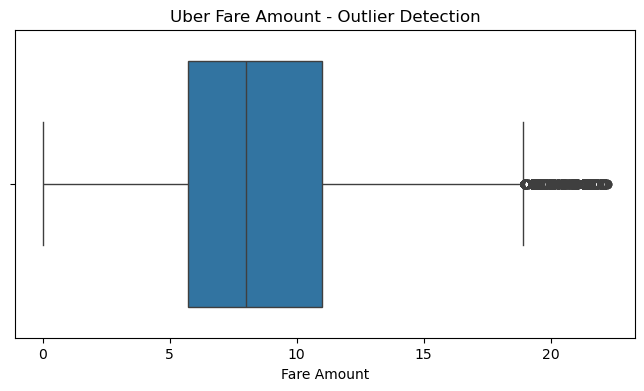

In [19]:
plt.figure(figsize=(8, 4))

sns.boxplot(x=df["fare_amount"])

plt.title("Uber Fare Amount - Outlier Detection")
plt.xlabel("Fare Amount")

plt.show()


In [20]:
def calculate_distance(lat1, lon1, lat2, lon2):

    # Convert degrees into radians
    lat1, lon1, lat2, lon2 = map(
        np.radians, [lat1, lon1, lat2, lon2]
    )

    # Haversine formula
    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2 +
        np.cos(lat1) * np.cos(lat2) *
        np.sin(dlon / 2) ** 2
    )

    c = 2 * np.arcsin(np.sqrt(a))

    # Earth's radius in kilometers
    return 6371 * c

In [21]:
# Calculate ride distance
df["distance"] = calculate_distance(
    df["pickup_latitude"],
    df["pickup_longitude"],
    df["dropoff_latitude"],
    df["dropoff_longitude"]
)

# Remove zero-distance and unrealistic long-distance rides
df = df[
    (df["distance"] > 0) &
    (df["distance"] < 200)
].copy()

print("\nDataset With Distance:")
print(df[["distance", "fare_amount"]].head())


Dataset With Distance:
   distance  fare_amount
0  1.683323          7.5
1  2.457590          7.7
2  5.036377         12.9
3  1.661683          5.3
4  4.475450         16.0


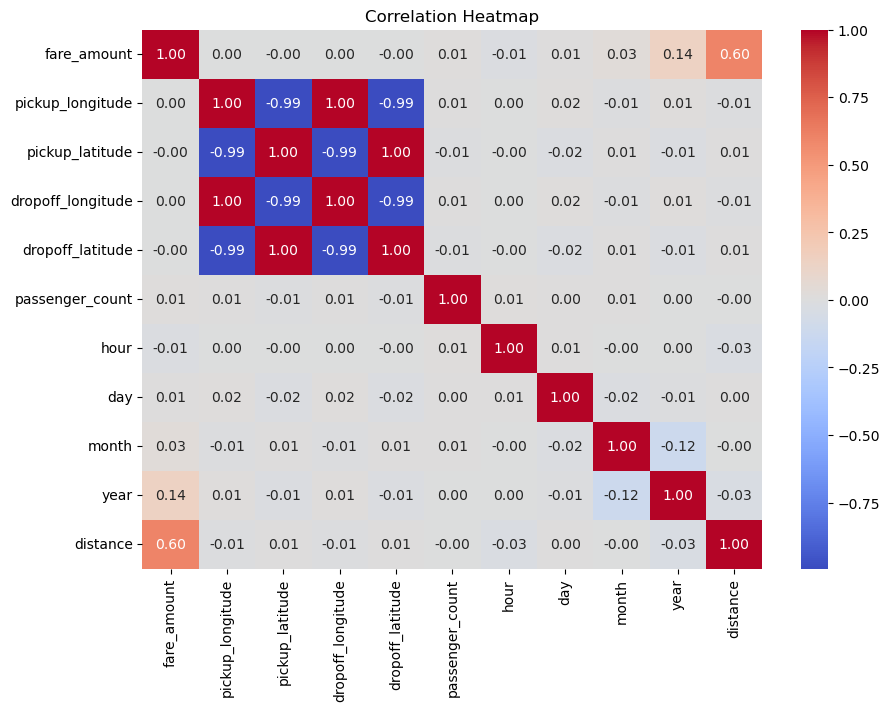


Correlation With Fare Amount:
fare_amount          1.000000
distance             0.596149
year                 0.135702
month                0.026649
passenger_count      0.012714
day                  0.006572
dropoff_longitude    0.002039
pickup_longitude     0.001201
pickup_latitude     -0.002022
dropoff_latitude    -0.002238
hour                -0.013129
Name: fare_amount, dtype: float64


In [22]:
plt.figure(figsize=(10, 7))

correlation = df.corr(numeric_only=True)

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

print("\nCorrelation With Fare Amount:")
print(correlation["fare_amount"].sort_values(ascending=False))

In [23]:
X = df[
    [
        "pickup_longitude",
        "pickup_latitude",
        "dropoff_longitude",
        "dropoff_latitude",
        "passenger_count",
        "hour",
        "day",
        "month",
        "year",
        "distance"
    ]
]

y = df["fare_amount"]

print("\nInput Features:")
print(X.head())

print("\nTarget Variable:")
print(y.head())


Input Features:
   pickup_longitude  pickup_latitude  dropoff_longitude  dropoff_latitude  \
0        -73.999817        40.738354         -73.999512         40.723217   
1        -73.994355        40.728225         -73.994710         40.750325   
2        -74.005043        40.740770         -73.962565         40.772647   
3        -73.976124        40.790844         -73.965316         40.803349   
4        -73.925023        40.744085         -73.973082         40.761247   

   passenger_count  hour  day  month  year  distance  
0                1    19    7      5  2015  1.683323  
1                1    20   17      7  2009  2.457590  
2                1    21   24      8  2009  5.036377  
3                3     8   26      6  2009  1.661683  
4                5    17   28      8  2014  4.475450  

Target Variable:
0     7.5
1     7.7
2    12.9
3     5.3
4    16.0
Name: fare_amount, dtype: float64


In [24]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("\nTraining Data:", X_train.shape)
print("Testing Data:", X_test.shape)


Training Data: (141340, 10)
Testing Data: (35336, 10)


In [25]:
lr_model = LinearRegression()

# Train the model
lr_model.fit(X_train, y_train)

# Predict fare prices
lr_predictions = lr_model.predict(X_test)

print("\nLinear Regression Model Trained Successfully!")


Linear Regression Model Trained Successfully!


In [26]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train)

# Predict fare prices
rf_predictions = rf_model.predict(X_test)

print("\nRandom Forest Model Trained Successfully!")


Random Forest Model Trained Successfully!


In [27]:
def evaluate_model(name, actual, predicted):

    r2 = r2_score(actual, predicted)

    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    mae = mean_absolute_error(actual, predicted)

    print("\n", name)
    print("R2 Score:", round(r2, 4))
    print("RMSE:", round(rmse, 4))
    print("MAE:", round(mae, 4))


# Evaluate Linear Regression
evaluate_model(
    "Linear Regression",
    y_test,
    lr_predictions
)

# Evaluate Random Forest
evaluate_model(
    "Random Forest Regression",
    y_test,
    rf_predictions
)


 Linear Regression
R2 Score: 0.326
RMSE: 3.426
MAE: 2.1656

 Random Forest Regression
R2 Score: 0.7821
RMSE: 1.9479
MAE: 1.3494


In [28]:
results = pd.DataFrame({

    "Model": [
        "Linear Regression",
        "Random Forest"
    ],

    "R2 Score": [
        r2_score(y_test, lr_predictions),
        r2_score(y_test, rf_predictions)
    ],

    "RMSE": [
        np.sqrt(mean_squared_error(y_test, lr_predictions)),
        np.sqrt(mean_squared_error(y_test, rf_predictions))
    ],

    "MAE": [
        mean_absolute_error(y_test, lr_predictions),
        mean_absolute_error(y_test, rf_predictions)
    ]

})

print("\nMODEL COMPARISON:")
print(results.to_string(index=False))

# Select the model with the highest R2 score
best_model = results.loc[
    results["R2 Score"].idxmax(), "Model"
]

print("\nBest Performing Model:", best_model)






MODEL COMPARISON:
            Model  R2 Score     RMSE      MAE
Linear Regression  0.326010 3.426038 2.165579
    Random Forest  0.782117 1.947946 1.349366

Best Performing Model: Random Forest


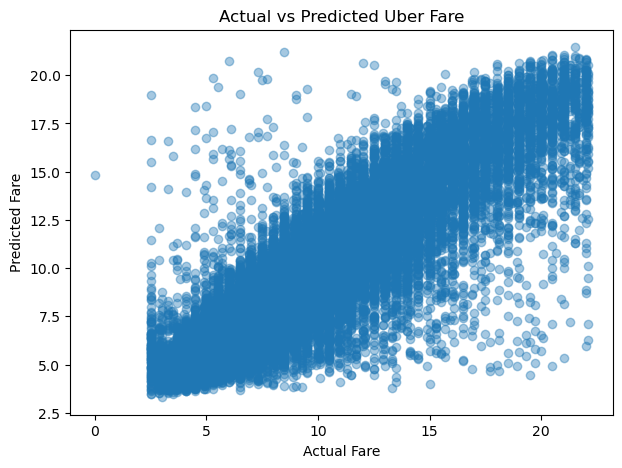

In [29]:

plt.figure(figsize=(7, 5))

plt.scatter(
    y_test,
    rf_predictions,
    alpha=0.4
)

plt.xlabel("Actual Fare")
plt.ylabel("Predicted Fare")

plt.title("Actual vs Predicted Uber Fare")

plt.show()

In [30]:
print("\nEnter New Ride Details:")

pickup_lon = float(input("Pickup Longitude: "))
pickup_lat = float(input("Pickup Latitude: "))

dropoff_lon = float(input("Drop-off Longitude: "))
dropoff_lat = float(input("Drop-off Latitude: "))

passengers = int(input("Number of Passengers: "))

hour = int(input("Pickup Hour (0-23): "))
day = int(input("Pickup Day (1-31): "))
month = int(input("Pickup Month (1-12): "))
year = int(input("Pickup Year: "))

# Calculate distance for the new ride
distance = calculate_distance(
    pickup_lat,
    pickup_lon,
    dropoff_lat,
    dropoff_lon
)

# Prepare new ride data in the same feature order
new_ride = pd.DataFrame([[
    pickup_lon,
    pickup_lat,
    dropoff_lon,
    dropoff_lat,
    passengers,
    hour,
    day,
    month,
    year,
    distance
]], columns=X.columns)

# Use the best performing model
if best_model == "Random Forest":
    predicted_fare = rf_model.predict(new_ride)[0]
else:
    predicted_fare = lr_model.predict(new_ride)[0]

print("\nPredicted Uber Ride Fare:", round(predicted_fare, 2))


Enter New Ride Details:


Pickup Longitude:  14.523648
Pickup Latitude:  125.5632489
Drop-off Longitude:  16.2356
Drop-off Latitude:  128.2648
Number of Passengers:  3
Pickup Hour (0-23):  12
Pickup Day (1-31):  23
Pickup Month (1-12):  6
Pickup Year:  2026



Predicted Uber Ride Fare: 13.14
